# Exploratory Data Analysis

This notebook explores grade-level Math and ELA proficiency patterns in Maryland public schools from 2023–2025 and examines their relationships with attendance and school-level student characteristics. The analysis also examines variable distributions and correlations to help inform the regression models developed in the next notebook.

## Setup and Load Analysis Data

Import the required libraries, define project paths, and load the analysis-ready dataset created during data integration.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
PROJECT_ROOT = Path.home() / "Documents" / "Maryland Education Project"
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

In [3]:
analysis_path = PROCESSED_DATA_DIR / "analysis_ready_2023_2025.csv"

df = pd.read_csv(
    analysis_path,
    dtype={
        "lea_id": "string",
        "school_id": "string"
    }
)

df.shape

(22102, 31)

### Initial Data Inspection

Inspect the analysis-ready dataset to verify its structure, column types, and contents before beginning exploratory analysis.

In [4]:
df.head()

,year,lea_id,lea_name,school_id,school_name,assessment,tested_count,proficient_count,proficient_pct,level1_pct,...,attendance_pct,more_20_pct,chronic_absentee_pct,special_school_type,farms_pct,multilingual_learner_pct,students_with_disabilities_pct,economically_disadvantaged_pct,gifted_talented_pct,total_student_count
0,2023,01,Allegany,0301,Flintstone Elementary,Mathematics 03,26,5,19.2,15.4,...,92.3,16.2,25.7,Elementary,60.7,*,14.0,54.2,*,214
1,2023,01,Allegany,0301,Flintstone Elementary,Mathematics 04,31,13,41.9,12.9,...,92.3,16.2,25.7,Elementary,60.7,*,14.0,54.2,*,214
2,2023,01,Allegany,0301,Flintstone Elementary,Mathematics 05,35,5,14.3,20.0,...,92.3,16.2,25.7,Elementary,60.7,*,14.0,54.2,*,214
3,2023,01,Allegany,0401,South Penn Elementary,Mathematics 03,62,19,30.6,25.8,...,88.7,34.3,45.0,Elementary,80.8,*,23.0,80.8,*,526
4,2023,01,Allegany,0401,South Penn Elementary,Mathematics 04,85,13,15.3,30.6,...,88.7,34.3,45.0,Elementary,80.8,*,23.0,80.8,*,526


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 22102 entries, 0 to 22101
Data columns (total 31 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   year                            22102 non-null  int64  
 1   lea_id                          22102 non-null  string 
 2   lea_name                        22102 non-null  str    
 3   school_id                       22102 non-null  string 
 4   school_name                     22102 non-null  str    
 5   assessment                      22102 non-null  str    
 6   tested_count                    22102 non-null  str    
 7   proficient_count                22102 non-null  str    
 8   proficient_pct                  22102 non-null  str    
 9   level1_pct                      22102 non-null  str    
 10  level2_pct                      22102 non-null  str    
 11  level3_pct                      22102 non-null  str    
 12  level4_pct                      22102 non-n

### Prepare Variables for Analysis

Convert school-level context variables to numeric values so they can be summarized, visualized, and used in correlation and regression analyses.

In [6]:
context_numeric_cols = [
    "attendance_pct",
    "more_20_pct",
    "chronic_absentee_pct",
    "farms_pct",
    "multilingual_learner_pct",
    "students_with_disabilities_pct",
    "economically_disadvantaged_pct",
    "gifted_talented_pct",
    "total_student_count"
]

# convert school-level percentages and enrollment to numeric values
df[context_numeric_cols] = df[context_numeric_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

df[context_numeric_cols].dtypes

attendance_pct                    float64
more_20_pct                       float64
chronic_absentee_pct              float64
farms_pct                         float64
multilingual_learner_pct          float64
students_with_disabilities_pct    float64
economically_disadvantaged_pct    float64
gifted_talented_pct               float64
total_student_count               float64
dtype: object

### Initial Missing Data Overview

Review missing values in the proficiency outcome and school-level context variables. Missingness is examined early because it affects the number of observations available for later analyses and regression models.

In [7]:
missing_counts = df[
    ["proficient_pct_numeric"] + context_numeric_cols
].isna().sum()

missing_pct = (
    df[
        ["proficient_pct_numeric"] + context_numeric_cols
    ].isna().mean() * 100
)

missing_summary = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_pct": missing_pct
})

missing_summary

,missing_count,missing_pct
proficient_pct_numeric,395,1.787169
attendance_pct,2484,11.238802
more_20_pct,1897,8.582934
chronic_absentee_pct,349,1.579043
farms_pct,1673,7.569451
multilingual_learner_pct,9465,42.824179
students_with_disabilities_pct,927,4.194191
economically_disadvantaged_pct,423,1.913854
gifted_talented_pct,7438,33.653063
total_student_count,234,1.058728


In [8]:
df.groupby(["year", "subject"])["proficient_pct_numeric"].apply(
    lambda x: x.isna().sum()
)

year  subject
2023  ELA        65
      Math       67
2024  ELA        65
      Math       73
2025  ELA        63
      Math       62
Name: proficient_pct_numeric, dtype: int64

## Proficiency Patterns

Begin by summarizing the distribution of Math and ELA proficiency before examining differences across grade levels.

In [9]:
df.groupby("subject")["proficient_pct_numeric"].describe()

,count,mean,std,min,25%,50%,75%,max
subject,,,,,,,,
ELA,10862.0,44.954824,21.120538,2.5,28.4,43.9,61.4,97.5
Math,10845.0,26.797040,21.409191,2.5,8.5,21.6,41.2,93.0


In [10]:
df.groupby(["grade", "subject"])["proficient_pct_numeric"].describe()

count       mean        std  min   25%    50%     75%   max
grade subject                                                              
3     ELA      2594.0  46.219429  21.111456  2.5  28.8  45.65  63.000  97.5
      Math     2593.0  38.691670  21.919694  2.5  20.2  36.10  56.300  93.0
4     ELA      2597.0  46.749750  21.564077  2.5  29.9  46.40  63.600  97.5
      Math     2597.0  30.985060  21.241543  2.5  13.1  26.90  46.600  87.8
5     ELA      2587.0  41.666989  20.959313  2.5  25.0  40.00  58.100  97.5
      Math     2587.0  26.751952  20.011310  2.5  10.0  22.20  40.000  91.2
6     ELA      1056.0  45.151515  20.503346  2.5  30.0  44.20  61.125  91.7
      Math     1056.0  16.714583  15.091142  2.5   2.5  11.80  25.200  68.8
7     ELA      1010.0  46.477426  20.335133  2.5  30.6  45.10  62.650  92.0
      Math     1009.0  14.631120  13.095497  2.5   2.5  10.60  21.800  64.7
8     ELA      1018.0  43.794008  20.823796  2.5  28.8  42.35  60.000  97.5
      Math     1003.0   8.172981   9.369732  2.5   2.5   2.50  10.500  61.4

### Proficiency by Grade and Subject

Mean proficiency is compared across grades 3–8 for Math and ELA to visualize how subject-level performance patterns vary by grade.

In [11]:
# group observations by grade and subject, then calculate the mean proficiency %
# for each grade-subject combination
mean_proficiency_by_grade = (
    df.groupby(["grade", "subject"])["proficient_pct_numeric"]
    .mean()
    # reshape subject from a row index into separate Math and ELA columns
    .unstack()
)

mean_proficiency_by_grade

subject,ELA,Math
grade,,
3,46.219429,38.691670
4,46.749750,30.985060
5,41.666989,26.751952
6,45.151515,16.714583
7,46.477426,14.631120
8,43.794008,8.172981


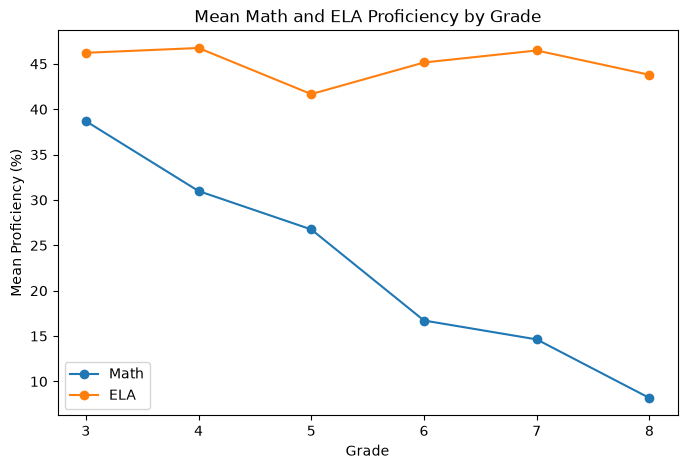

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(
    mean_proficiency_by_grade.index,
    mean_proficiency_by_grade["Math"],
    marker = "o",
    label = "Math"
)

plt.plot(
    mean_proficiency_by_grade.index,
    mean_proficiency_by_grade["ELA"],
    marker = "o",
    label = "ELA"
)

plt.xlabel("Grade")
plt.ylabel("Mean Proficiency (%)")
plt.title("Mean Math and ELA Proficiency by Grade")
plt.legend()

plt.savefig(
    "../figures/mean_proficiency_by_grade_subject.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

The mean percentage of students scoring proficient on the Math MCAP decreases substantially from grades 3 to 8. This pattern may be influenced in part by differences in assessment participation, since some students in grades 6–8 may take course-based mathematics assessments rather than the corresponding grade-level Math MCAP. Therefore, grade-level Math results may not represent all students enrolled in each grade. 

Mean ELA proficiency is higher than mean Math proficiency at every grade and remains relatively stable across grades 3–8. The difference between mean ELA and Math proficiency also becomes larger in the later grades.

### Proficiency by Year and Subject

Mean proficiency is compared across 2023–2025 to examine whether Math and ELA performance patterns changed over time.

In [13]:
# calculate overall mean proficiency for each year and subject
mean_proficiency_by_year = (
    df.groupby(["year", "subject"])["proficient_pct_numeric"]
    .mean()
    # reshape subject into separate Math and ELA columns
    .unstack()
)

mean_proficiency_by_year

subject,ELA,Math
year,,
2023,44.079670,25.648540
2024,44.486460,26.360814
2025,46.306319,28.390899


In [14]:
# calculate mean Math proficiency for each year and grade
# and reshape grades into columns for plotting
math_by_year_grade = (
    df[df["subject"] == "Math"]
    .groupby(["year", "grade"])["proficient_pct_numeric"]
    .mean()
    .unstack()
)

math_by_year_grade

grade,3,4,5,6,7,8
year,,,,,,
2023,37.816416,29.993764,25.066976,15.112668,13.684384,7.897289
2024,38.021965,30.430485,26.705220,16.315230,14.064392,7.536937
2025,40.240209,32.532717,28.485615,18.890504,16.124484,9.070414


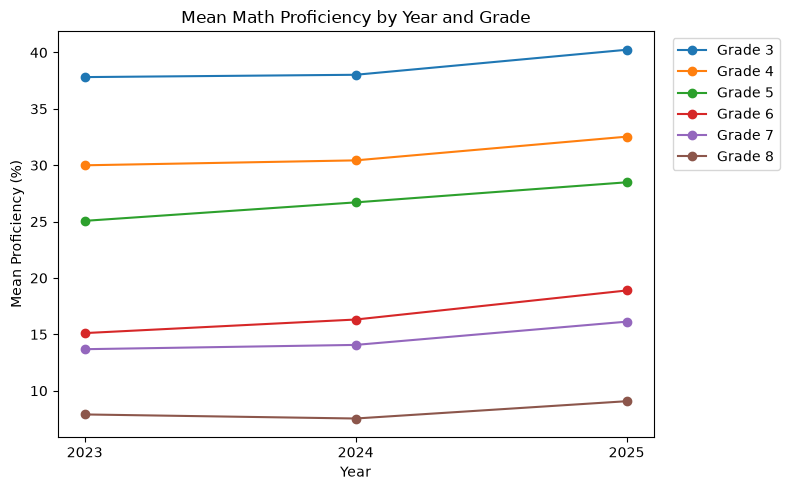

In [15]:
plt.figure(figsize=(8, 5))

for grade in math_by_year_grade.columns:
    plt.plot(
        math_by_year_grade.index,
        math_by_year_grade[grade],
        marker="o",
        label=f"Grade {grade}"
    )

plt.xlabel("Year")
plt.ylabel("Mean Proficiency (%)")
plt.title("Mean Math Proficiency by Year and Grade")
plt.xticks(math_by_year_grade.index)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

plt.show()

In [16]:
# calculate mean ELA proficiency for each year and grade
# and reshape grades into columns for plotting
ela_by_year_grade = (
    df[df["subject"] == "ELA"]
    .groupby(["year", "grade"])["proficient_pct_numeric"]
    .mean()
    .unstack()
)

ela_by_year_grade

grade,3,4,5,6,7,8
year,,,,,,
2023,45.880347,46.757506,39.779954,44.292183,43.919219,43.511869
2024,44.517803,47.165127,42.234107,44.242241,45.350296,42.685588
2025,48.262500,46.326127,42.989095,47.036499,50.114159,45.178006


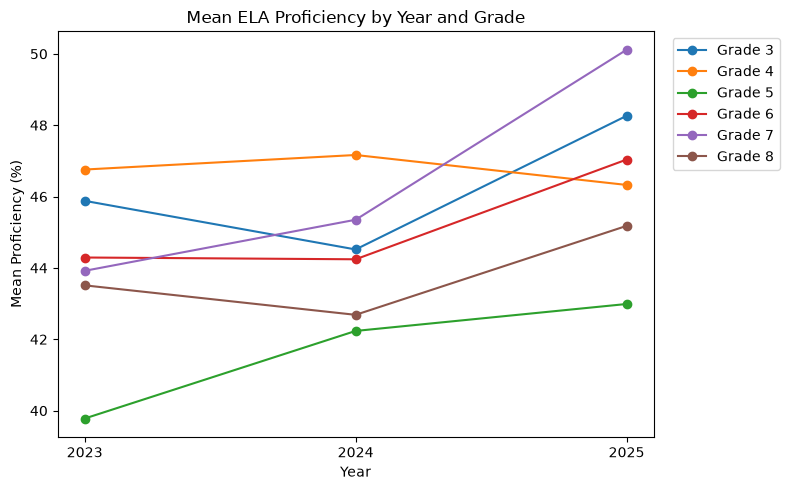

In [17]:
plt.figure(figsize=(8, 5))

for grade in ela_by_year_grade.columns:
    plt.plot(
        ela_by_year_grade.index,
        ela_by_year_grade[grade],
        marker="o",
        label=f"Grade {grade}"
    )

plt.xlabel("Year")
plt.ylabel("Mean Proficiency (%)")
plt.title("Mean ELA Proficiency by Year and Grade")
plt.xticks(ela_by_year_grade.index)

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

plt.show()

Across all grades, mean Math proficiency was higher in 2025 than in 2023 and 2024. The differences in Math proficiency across grades also remained apparent in each year, with lower mean proficiency in the later grades.

ELA proficiency varied less consistently across years and grades. However, most grades had higher mean ELA proficiency in 2025 than in 2023. Grade 7 showed the largest increase over this period, while Grade 4 remained relatively stable.

## Attendance and Absenteeism

Attendance-related variables are examined to understand their distributions before evaluating their relationships with Math and ELA proficiency.

In [18]:
# attendance variables included in exploratory analysis
attendance_cols = [
    "attendance_pct",
    "chronic_absentee_pct",
    "more_20_pct"
]

# retain one record per school-year for descriptive summaries
# to avoid counting repeated grade and subject observations
school_year_context = (
    df.drop_duplicates(subset=["year", "lea_id", "school_id"])
)

school_year_context.shape

(3389, 31)

In [19]:
# summarize attendance variables across unique school-year records
school_year_context[attendance_cols].describe()

,attendance_pct,chronic_absentee_pct,more_20_pct
count,3036.000000,3343.000000,3113.000000
mean,91.996476,26.078223,18.813685
std,3.216278,14.244178,11.948012
min,59.400000,5.100000,5.100000
25%,91.400000,16.100000,10.800000
50%,92.900000,23.100000,15.600000
75%,93.800000,32.400000,22.900000
max,94.900000,94.200000,86.400000


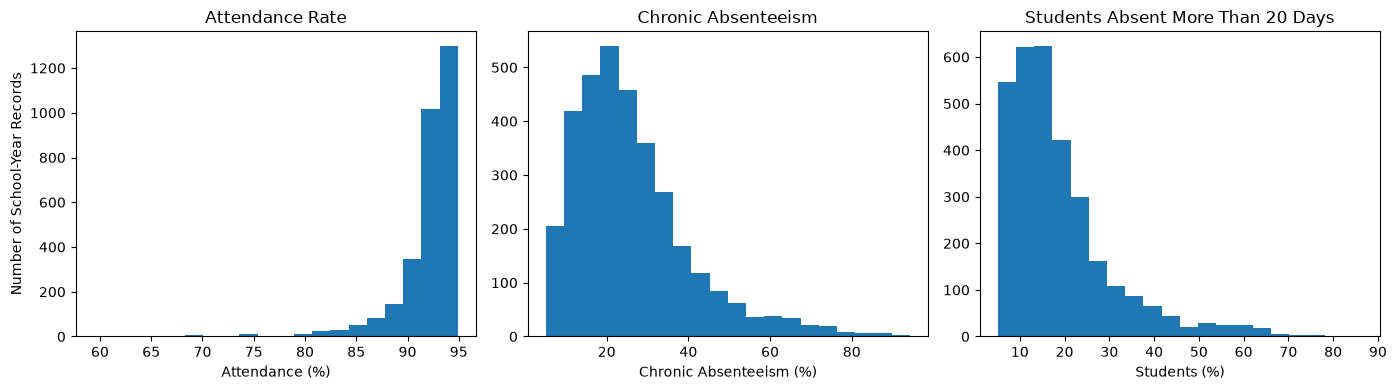

In [20]:
# plot unique school-year records so schools with more assessment rows are not overrepresented
fig, axarr = plt.subplots(1, 3, figsize=(14, 4))

axarr[0].hist(school_year_context["attendance_pct"].dropna(), bins=20)
axarr[0].set_title("Attendance Rate")
axarr[0].set_xlabel("Attendance (%)")
axarr[0].set_ylabel("Number of School-Year Records")

axarr[1].hist(school_year_context["chronic_absentee_pct"].dropna(), bins=20)
axarr[1].set_title("Chronic Absenteeism")
axarr[1].set_xlabel("Chronic Absenteeism (%)")

axarr[2].hist(school_year_context["more_20_pct"].dropna(), bins=20)
axarr[2].set_title("Students Absent More Than 20 Days")
axarr[2].set_xlabel("Students (%)")

plt.tight_layout()
plt.show()

Attendance rates are concentrated in the low-to-mid 90% range, with relatively few school-year records having substantially lower attendance rates. Chronic absenteeism and the percentage of students absent more than 20 days are both right-skewed, with most school-year records concentrated at lower percentages and fewer records having very high absenteeism rates.

### Relationship Between Attendance and Proficiency

Scatterplots are used to examine the relationship between school attendance rates and MCAP proficiency. Math and ELA are examined separately because proficiency patterns differ substantially by subject.

In [21]:
# create subject-specific datasets for comparing attendance and proficiency
math_df = df[df["subject"] == "Math"]
ela_df = df[df["subject"] == "ELA"]

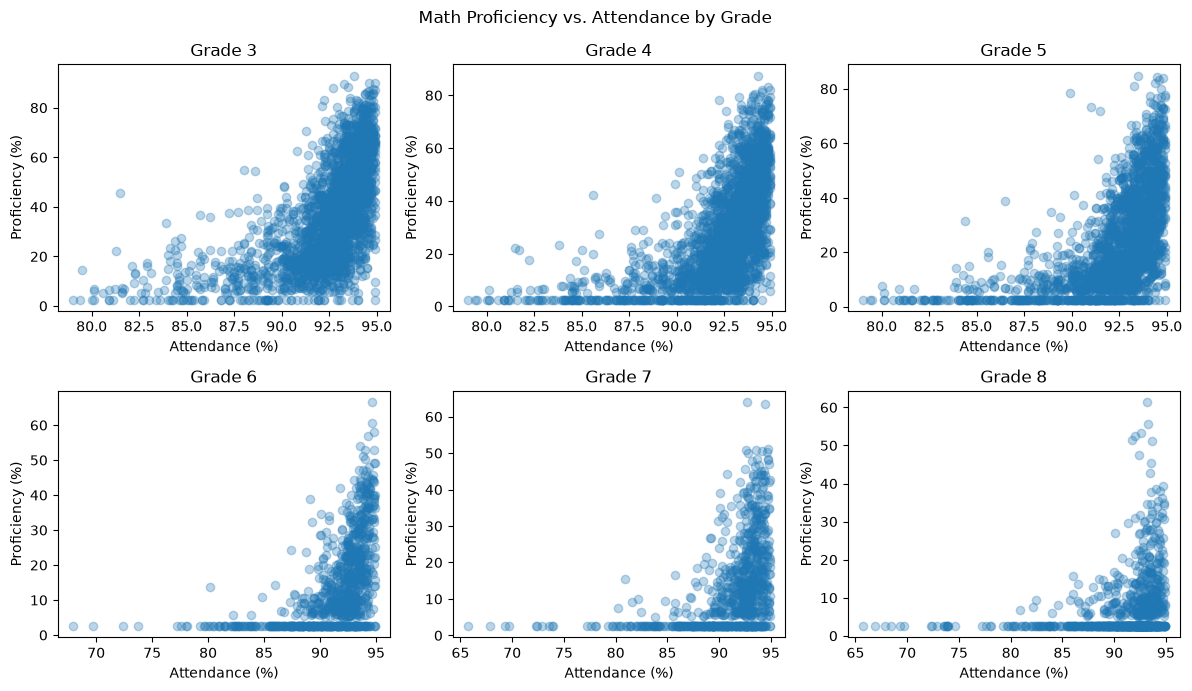

In [22]:
fig, axarr = plt.subplots(2, 3, figsize=(12, 7))

# flatten the 2x3 array of subplot axes into a 1D sequence
# then pair each subplot with one grade (3 through 8)
for ax, grade in zip(axarr.flatten(), sorted(math_df["grade"].unique())):
    # keep only math observations for current grade
    grade_data = math_df[math_df["grade"] == grade]

    ax.scatter(
        grade_data["attendance_pct"],
        grade_data["proficient_pct_numeric"],
        alpha=0.3
    )

    ax.set_title(f"Grade {grade}")
    ax.set_xlabel("Attendance (%)")
    ax.set_ylabel("Proficiency (%)")

plt.suptitle("Math Proficiency vs. Attendance by Grade")
plt.tight_layout()

plt.show()

In [23]:
# calculate correlation between attendance and Math proficiency 
# separately within each grade
math_attendance_corr = (
    math_df.groupby("grade")
    .apply(
        lambda x: x["attendance_pct"].corr(x["proficient_pct_numeric"]),
        include_groups=False
    )
)

math_attendance_corr

grade
3    0.579486
4    0.564202
5    0.543936
6    0.501496
7    0.412696
8    0.262151
dtype: float64

Across grades 3–8, Math proficiency is positively associated with school attendance. The strength of the linear relationship decreases across the later grades, with the strongest correlations observed in grades 3–5 and the weakest in Grade 8. However, substantial variation in proficiency remains among schools with similar attendance rates, indicating that attendance alone does not explain differences in Math proficiency.

The concentration of observations near 2.5% proficiency reflects the treatment of low-bounded MCAP proficiency values and should not be interpreted as exact proficiency rates.

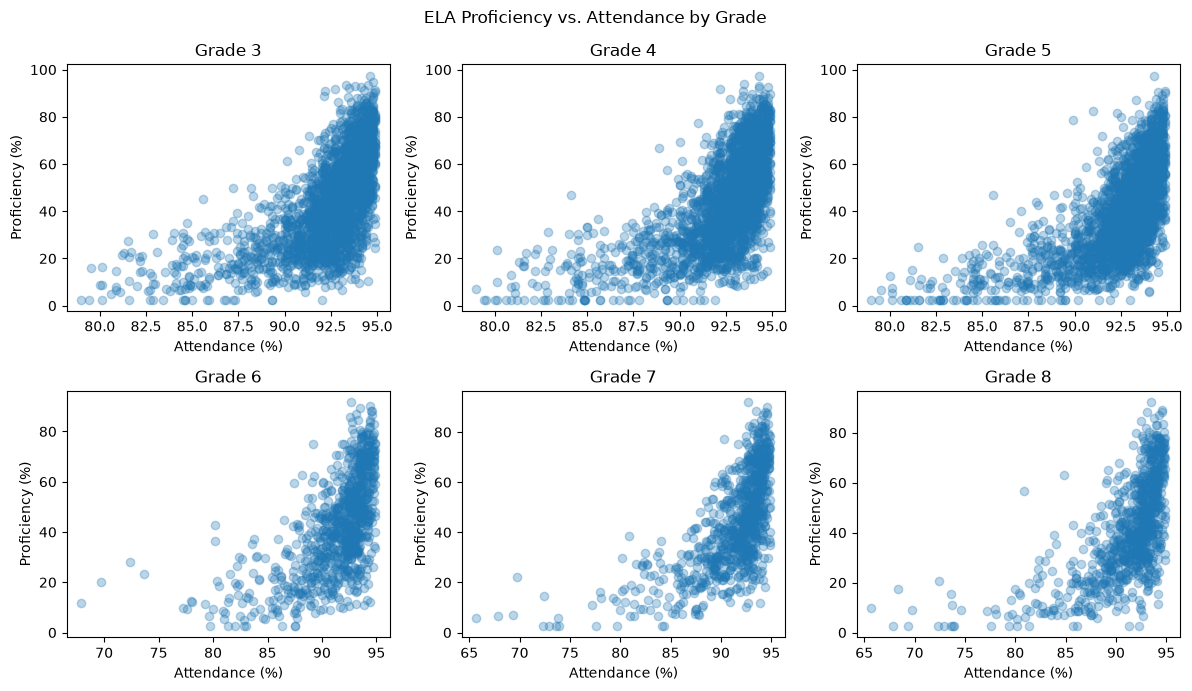

In [24]:
fig, axarr = plt.subplots(2, 3, figsize=(12, 7))

for ax, grade in zip(axarr.flatten(), sorted(ela_df["grade"].unique())):
    grade_data = ela_df[ela_df["grade"] == grade]

    ax.scatter(
        grade_data["attendance_pct"],
        grade_data["proficient_pct_numeric"],
        alpha=0.3
    )

    ax.set_title(f"Grade {grade}")
    ax.set_xlabel("Attendance (%)")
    ax.set_ylabel("Proficiency (%)")

plt.suptitle("ELA Proficiency vs. Attendance by Grade")
plt.tight_layout()

plt.show()

In [25]:
# calculate the correlation between attendance and ELA proficiency
# separately within each grade
ela_attendance_corr = (
    ela_df.groupby("grade")
    .apply(
        lambda x: x["attendance_pct"].corr(x["proficient_pct_numeric"]),
        include_groups=False
    )
)

ela_attendance_corr

grade
3    0.620372
4    0.626953
5    0.628212
6    0.599634
7    0.634011
8    0.615914
dtype: float64

ELA proficiency is positively associated with school attendance across grades 3–8. The correlations are relatively consistent across grades, ranging from approximately 0.60 to 0.63. In contrast to Math, where the relationship between attendance and proficiency becomes weaker in the later grades, the association between attendance and ELA proficiency remains relatively stable across grades.

## School Characteristics and Proficiency

Correlations are examined between proficiency and school-level attendance and student characteristics to identify relationships that may warrant further investigation and inclusion in later statistical models.

### Overall Correlations with Proficiency

In [26]:
context_cols = [
    "attendance_pct",
    "chronic_absentee_pct",
    "more_20_pct",
    "farms_pct",
    "multilingual_learner_pct",
    "students_with_disabilities_pct",
    "economically_disadvantaged_pct",
    "gifted_talented_pct"
]

In [27]:
context_correlations = pd.DataFrame({
    # calculate correlation between each school characteristic
    # and Math proficiency (do same for ELA next)
    "Math": [
        math_df[col].corr(math_df["proficient_pct_numeric"])
        for col in context_cols
    ],
    "ELA": [
        ela_df[col].corr(ela_df["proficient_pct_numeric"])
        for col in context_cols
    ]
}, index=context_cols)

context_correlations

,Math,ELA
attendance_pct,0.485773,0.596978
chronic_absentee_pct,-0.583072,-0.711425
more_20_pct,-0.537670,-0.648568
farms_pct,-0.697422,-0.820533
multilingual_learner_pct,-0.311565,-0.419092
students_with_disabilities_pct,-0.032380,-0.150159
economically_disadvantaged_pct,-0.648956,-0.787753
gifted_talented_pct,-0.021967,0.279325


In [28]:
# count the observations available for each correlation
# counts differ because some school characteristics have more missing data than others
context_corr_counts = pd.DataFrame({
    "Math": [
        math_df[[col, "proficient_pct_numeric"]].dropna().shape[0]
        for col in context_cols
    ],
    "ELA": [
        ela_df[[col, "proficient_pct_numeric"]].dropna().shape[0]
        for col in context_cols
    ]
}, index=context_cols)

context_corr_counts

,Math,ELA
attendance_pct,9669,9679
chronic_absentee_pct,10718,10733
more_20_pct,9967,9981
farms_pct,10098,10111
multilingual_learner_pct,6312,6319
students_with_disabilities_pct,10548,10563
economically_disadvantaged_pct,10720,10734
gifted_talented_pct,7318,7331


Multilingual learner and gifted/talented percentages have fewer usable observations than the other school-level characteristics. Relationships involving these variables should therefore be interpreted with consideration of their higher levels of missing data.

### Chronic Absenteeism and Proficiency

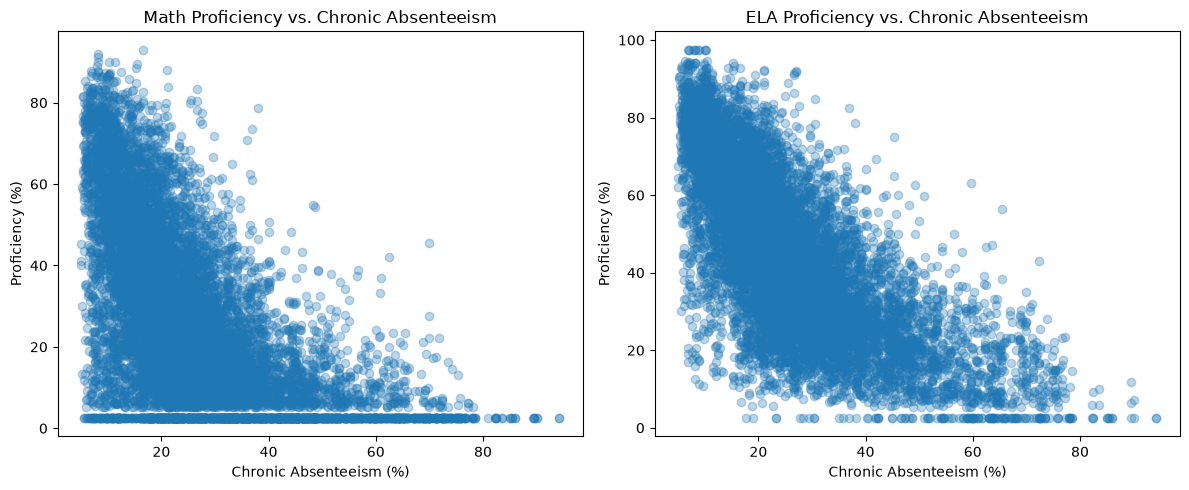

In [29]:
fig, axarr = plt.subplots(1, 2, figsize=(12, 5))

axarr[0].scatter(
    math_df["chronic_absentee_pct"],
    math_df["proficient_pct_numeric"],
    alpha=0.3
)

axarr[0].set_title("Math Proficiency vs. Chronic Absenteeism")
axarr[0].set_xlabel("Chronic Absenteeism (%)")
axarr[0].set_ylabel("Proficiency (%)")

axarr[1].scatter(
    ela_df["chronic_absentee_pct"],
    ela_df["proficient_pct_numeric"],
    alpha=0.3
)

axarr[1].set_title("ELA Proficiency vs. Chronic Absenteeism")
axarr[1].set_xlabel("Chronic Absenteeism (%)")
axarr[1].set_ylabel("Proficiency (%)")

plt.tight_layout()

plt.savefig(
    "../figures/proficiency_vs_chronic_absenteeism.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Chronic absenteeism is negatively associated with proficiency in both Math and ELA. Higher chronic absenteeism rates generally correspond with lower proficiency rates, although substantial variation remains among observations with similar absenteeism rates. The negative relationship is stronger for ELA than for Math based on the overall correlations.

### Correlation Among Related School Characteristics
Some school-level variables measure similar concepts. Their correlations are examined to identify potentially redundant predictors before regression modeling.

In [30]:
# check for overlap among three attendance-related measures
attendance_correlations = (
    school_year_context[attendance_cols]
    .corr()
)

attendance_correlations

,attendance_pct,chronic_absentee_pct,more_20_pct
attendance_pct,1.000000,-0.921870,-0.936661
chronic_absentee_pct,-0.921870,1.000000,0.975615
more_20_pct,-0.936661,0.975615,1.000000


The three attendance-related measures are highly correlated. Attendance rate is strongly negatively correlated with chronic absenteeism and the percentage of students absent more than 20 days, while the two absenteeism measures are strongly positively correlated with each other. Because these variables contain substantial overlapping information, including all three as predictors in the same regression model may introduce multicollinearity and will be considered during model development.

In [31]:
# compare the two measures of school-level economic disadvantage
socioeconomic_cols = [
    "farms_pct",
    "economically_disadvantaged_pct"
]

school_year_context[socioeconomic_cols].corr()

,farms_pct,economically_disadvantaged_pct
farms_pct,1.000000,0.925106
economically_disadvantaged_pct,0.925106,1.000000


FARMS and economically disadvantaged percentages are highly positively correlated (r = 0.93), indicating substantial overlap between the two school-level measures. Including both variables in the same regression model may introduce multicollinearity, so their use as predictors will be evaluated during model development.

### FARMS and Proficiency

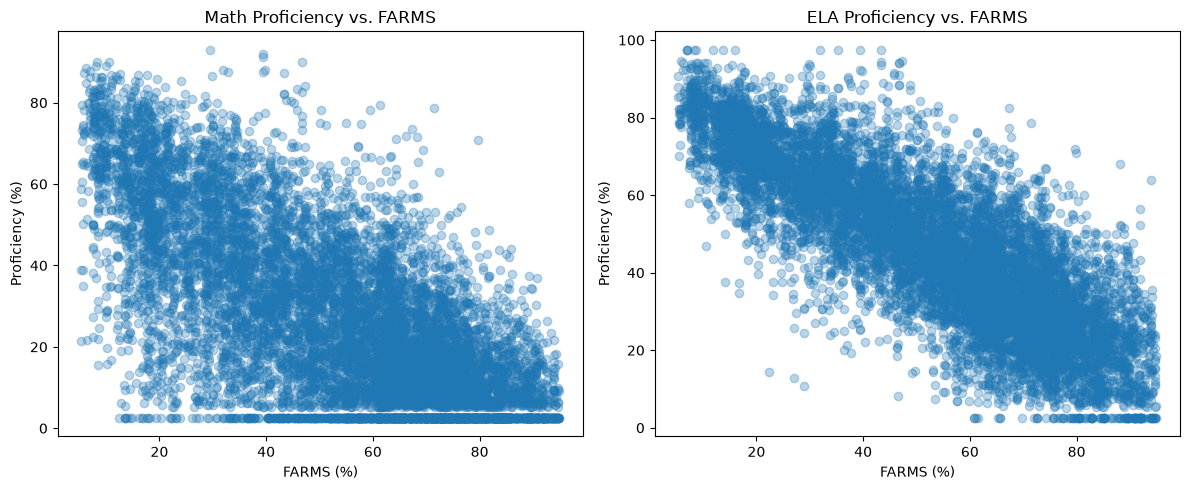

In [32]:
fig, axarr = plt.subplots(1, 2, figsize=(12, 5))

axarr[0].scatter(
    math_df["farms_pct"],
    math_df["proficient_pct_numeric"],
    alpha=0.3
)

axarr[0].set_title("Math Proficiency vs. FARMS")
axarr[0].set_xlabel("FARMS (%)")
axarr[0].set_ylabel("Proficiency (%)")

axarr[1].scatter(
    ela_df["farms_pct"],
    ela_df["proficient_pct_numeric"],
    alpha=0.3
)

axarr[1].set_title("ELA Proficiency vs. FARMS")
axarr[1].set_xlabel("FARMS (%)")
axarr[1].set_ylabel("Proficiency (%)")

plt.tight_layout()

plt.savefig(
    "../figures/proficiency_vs_farms.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Higher FARMS percentages are associated with lower proficiency in both Math and ELA. The negative relationship is particularly strong for ELA, although substantial variation in proficiency remains among observations with similar FARMS percentages. These relationships are descriptive and do not indicate that FARMS participation causes differences in proficiency.

### Gifted/Talented Participation

In [33]:
school_year_context["gifted_talented_pct"].describe()

count    2304.000000
mean       15.681120
std        10.987048
min         5.100000
25%         8.100000
50%        12.000000
75%        18.900000
max        68.300000
Name: gifted_talented_pct, dtype: float64

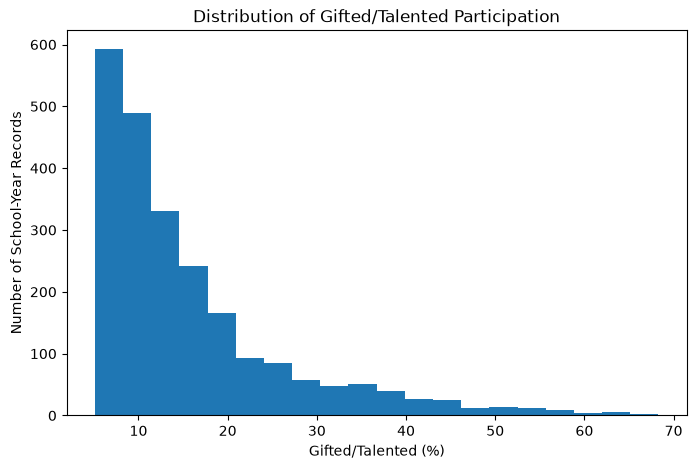

In [34]:
plt.figure(figsize=(8, 5))

plt.hist(
    school_year_context["gifted_talented_pct"].dropna(),
    bins=20
)

plt.xlabel("Gifted/Talented (%)")
plt.ylabel("Number of School-Year Records")
plt.title("Distribution of Gifted/Talented Participation")

plt.show()

Gifted/talented participation is right-skewed. The median school-year GT percentage is 12.0%, while the mean is 15.7%, reflecting a smaller number of schools with substantially higher GT percentages. GT percentage also has more missing observations than most of the other school-level characteristics.

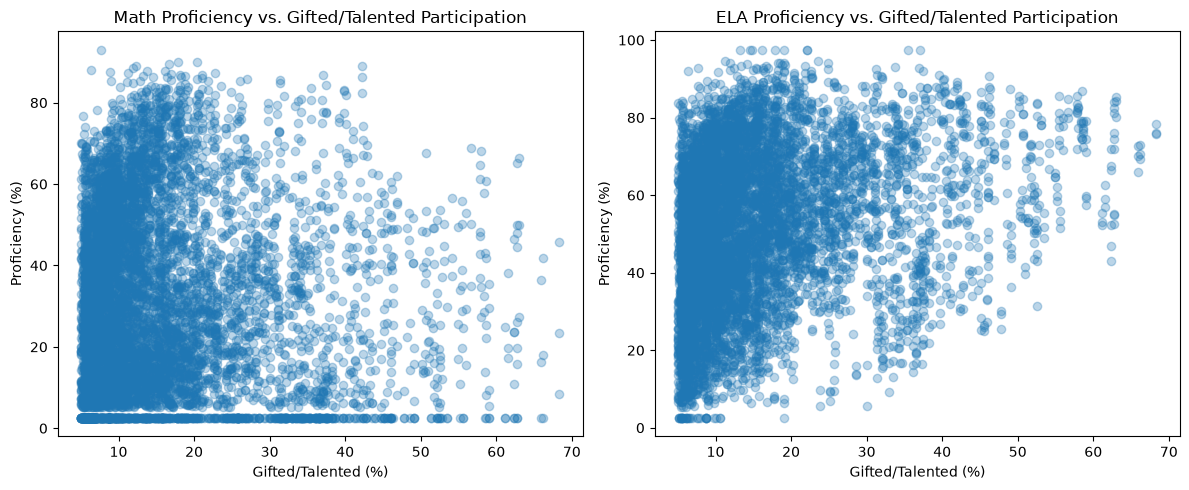

In [35]:
fig, axarr = plt.subplots(1, 2, figsize=(12, 5))

axarr[0].scatter(
    math_df["gifted_talented_pct"],
    math_df["proficient_pct_numeric"],
    alpha=0.3
)

axarr[0].set_title("Math Proficiency vs. Gifted/Talented Participation")
axarr[0].set_xlabel("Gifted/Talented (%)")
axarr[0].set_ylabel("Proficiency (%)")

axarr[1].scatter(
    ela_df["gifted_talented_pct"],
    ela_df["proficient_pct_numeric"],
    alpha=0.3
)

axarr[1].set_title("ELA Proficiency vs. Gifted/Talented Participation")
axarr[1].set_xlabel("Gifted/Talented (%)")
axarr[1].set_ylabel("Proficiency (%)")

plt.tight_layout()
plt.show()

In [36]:
# calculate correlations separately by grade because pooling grades
# can mask relationships that differ across grade levels
gt_corr_by_grade = pd.DataFrame({
    "Math": math_df.groupby("grade").apply(
        lambda x: x["gifted_talented_pct"].corr(x["proficient_pct_numeric"]),
        include_groups=False
    ),
    "ELA": ela_df.groupby("grade").apply(
        lambda x: x["gifted_talented_pct"].corr(x["proficient_pct_numeric"]),
        include_groups=False
    )
})

gt_corr_by_grade

,Math,ELA
grade,,
3,0.307746,0.314915
4,0.329277,0.317312
5,0.345519,0.335115
6,0.573103,0.354336
7,0.169642,0.377263
8,0.164895,0.373890


Although the overall correlation between gifted/talented participation and Math proficiency is near zero, grade-specific correlations are positive across all grades. The relationship is moderate in grades 3–5, strongest in Grade 6, and weaker in grades 7–8. This suggests that the overall Math correlation masks differences associated with grade.

For ELA, gifted/talented participation is positively associated with proficiency across all grades, with relatively consistent correlations of approximately 0.31–0.37. These results should be interpreted with consideration of the higher level of missing data for gifted/talented participation.

In [37]:
# compare GT participation across grades to investigate why the
# pooled Math correlation differs from within-grade correlations
gt_by_grade = (
    math_df.groupby("grade")["gifted_talented_pct"]
    .describe()
)

gt_by_grade

,count,mean,std,min,25%,50%,75%,max
grade,,,,,,,,
3,1679.0,12.116677,6.755196,5.1,7.4,10.20,14.800,54.2
4,1689.0,12.141859,6.786635,5.1,7.4,10.20,14.900,54.2
5,1692.0,12.146099,6.779065,5.1,7.4,10.20,14.825,54.2
6,768.0,23.678516,13.747456,5.2,12.6,20.35,32.825,68.3
7,753.0,23.985259,13.693314,5.2,13.1,20.60,33.000,68.3
8,747.0,23.979116,13.698209,5.2,13.1,20.60,32.950,68.3


Gifted/talented participation differs substantially by grade level. Mean GT participation is approximately 12% in grades 3–5 compared with approximately 24% in grades 6–8. At the same time, Math proficiency is substantially lower in the later grades.

These between-grade differences help explain why the overall correlation between GT participation and Math proficiency is near zero even though the relationship is positive within every grade. Pooling grades combines the within-grade association with substantial differences in both GT participation and Math proficiency across grade levels. This further supports accounting for grade in later statistical models.

### Students with Disabilities

In [38]:
school_year_context["students_with_disabilities_pct"].describe()

count    3262.000000
mean       13.764838
std         5.591081
min         5.100000
25%        10.200000
50%        12.800000
75%        16.000000
max        94.100000
Name: students_with_disabilities_pct, dtype: float64

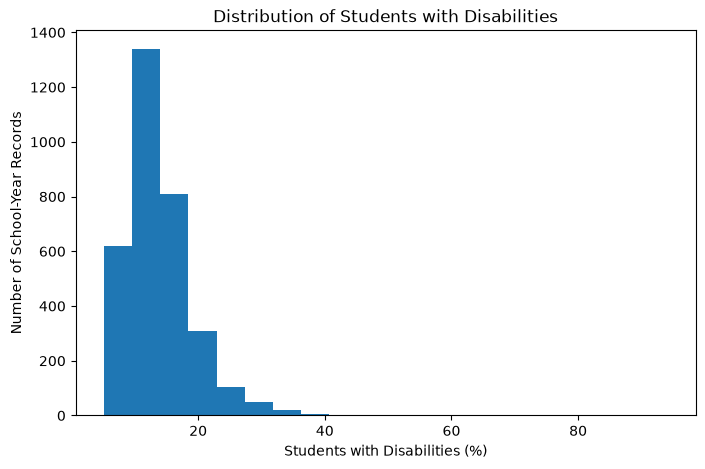

In [39]:
plt.figure(figsize=(8, 5))

plt.hist(
    school_year_context["students_with_disabilities_pct"].dropna(),
    bins=20
)

plt.xlabel("Students with Disabilities (%)")
plt.ylabel("Number of School-Year Records")
plt.title("Distribution of Students with Disabilities")

plt.show()

The percentage of students with disabilities is concentrated primarily around 10–16% of students, with a right-skewed distribution and a small number of school-year records having substantially higher percentages.

In [40]:
# calculate grade-specific correlations to determine whether relationship
# between SWD percentage and proficiency differs by grade
swd_corr_by_grade = pd.DataFrame({
    "Math": math_df.groupby("grade").apply(
        lambda x: x["students_with_disabilities_pct"].corr(
            x["proficient_pct_numeric"]
        ),
        include_groups=False
    ),
    "ELA": ela_df.groupby("grade").apply(
        lambda x: x["students_with_disabilities_pct"].corr(
            x["proficient_pct_numeric"]
        ),
        include_groups=False
    )
})

swd_corr_by_grade

,Math,ELA
grade,,
3,0.003810,-0.032570
4,-0.004728,-0.036026
5,0.010423,-0.030055
6,-0.371230,-0.445382
7,-0.424180,-0.496585
8,-0.273029,-0.449847


In [41]:
# compare SWD percentages across grades to determine whether differences
# in the predictor itself help explain the grade-specific correlations
swd_by_grade = (
    math_df.groupby("grade")["students_with_disabilities_pct"]
    .describe()
)

swd_by_grade

,count,mean,std,min,25%,50%,75%,max
grade,,,,,,,,
3,2542.0,13.980370,5.290175,5.1,10.3,13.1,16.500,41.1
4,2543.0,13.986001,5.291772,5.1,10.3,13.1,16.500,41.1
5,2528.0,14.011511,5.313200,5.1,10.3,13.1,16.600,41.1
6,1026.0,13.471832,6.534244,5.1,9.8,12.2,15.375,94.1
7,977.0,13.596520,6.530804,5.1,9.9,12.3,15.600,94.1
8,968.0,13.601446,6.549348,5.1,9.9,12.3,15.525,94.1


Students with disabilities percentages are relatively similar across grades, with mean percentages ranging from approximately 13.5% to 14.0%. However, the relationship between SWD percentage and proficiency differs substantially by grade.

In grades 3–5, SWD percentage has little linear association with either Math or ELA proficiency. In grades 6–8, higher SWD percentages are moderately associated with lower proficiency in both subjects. This variation across grades is obscured by the weaker overall correlations and further demonstrates the importance of accounting for grade when examining school-level characteristics.

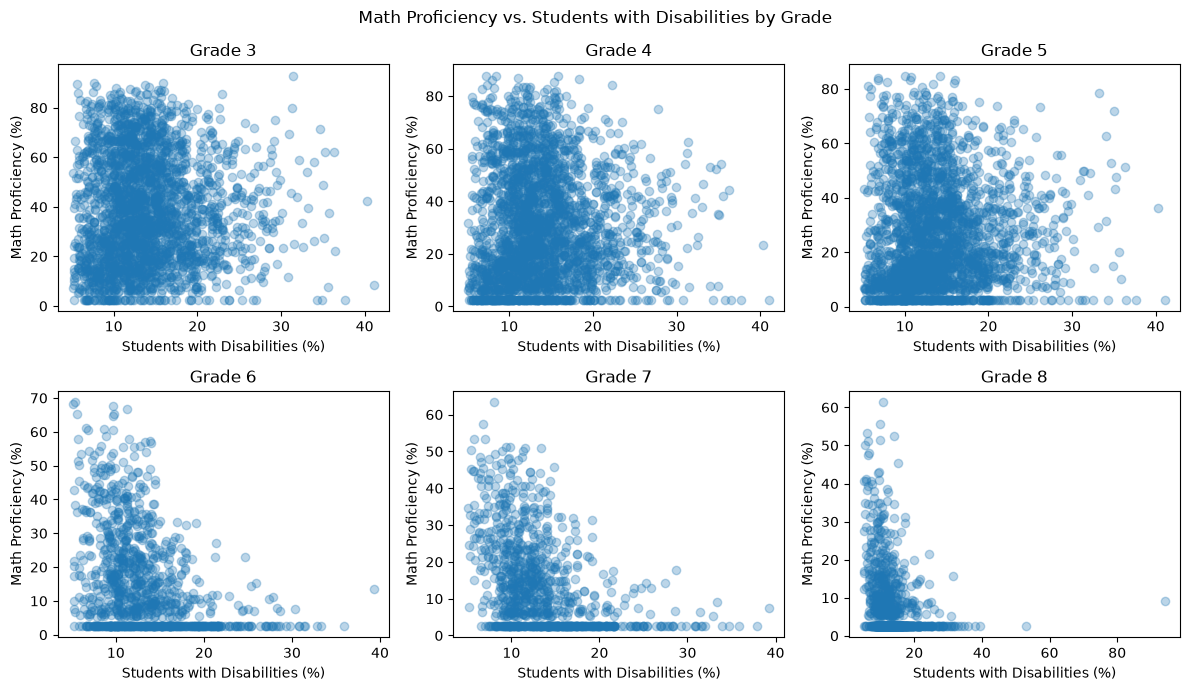

In [42]:
fig, axarr = plt.subplots(2, 3, figsize=(12, 7))

# flatten the 2x3 array of subplots and pair each subplot with one grade
for ax, grade in zip(axarr.flatten(), sorted(math_df["grade"].unique())):
    grade_data = math_df[math_df["grade"] == grade]

    ax.scatter(
        grade_data["students_with_disabilities_pct"],
        grade_data["proficient_pct_numeric"],
        alpha=0.3
    )

    ax.set_title(f"Grade {grade}")
    ax.set_xlabel("Students with Disabilities (%)")
    ax.set_ylabel("Math Proficiency (%)")

plt.suptitle("Math Proficiency vs. Students with Disabilities by Grade")
plt.tight_layout()
plt.show()

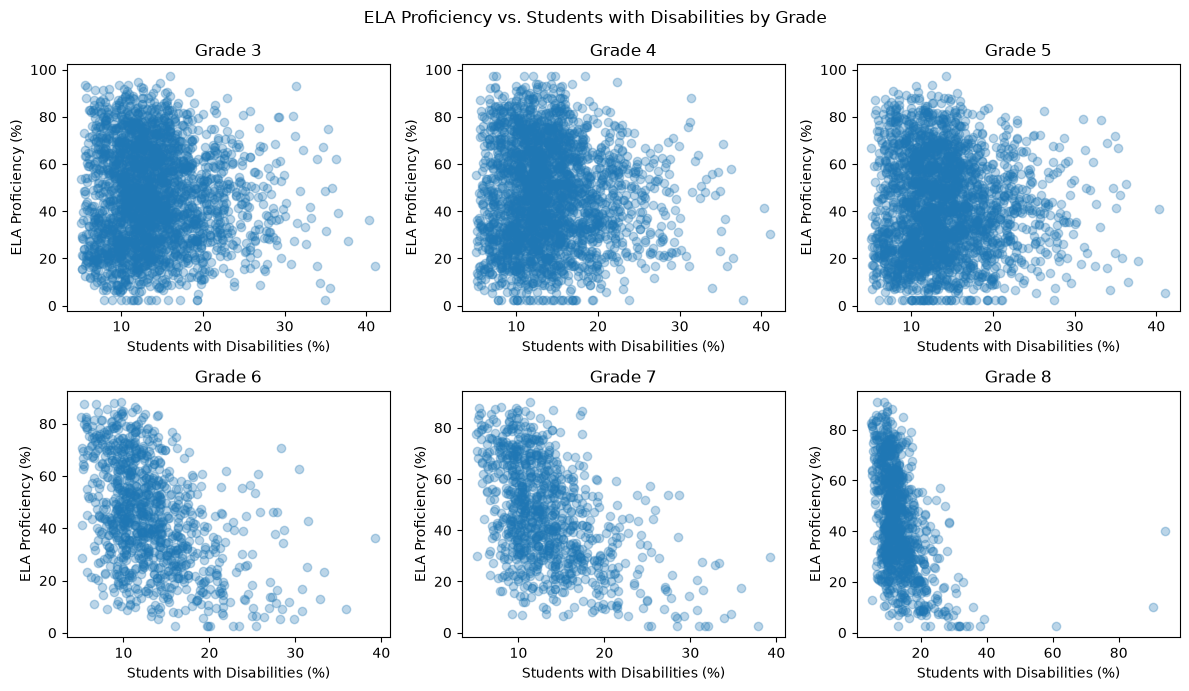

In [43]:
fig, axarr = plt.subplots(2, 3, figsize=(12, 7))

# flatten the 2x3 array of subplots and pair each subplot with one grade
for ax, grade in zip(axarr.flatten(), sorted(ela_df["grade"].unique())):
    grade_data = ela_df[ela_df["grade"] == grade]

    ax.scatter(
        grade_data["students_with_disabilities_pct"],
        grade_data["proficient_pct_numeric"],
        alpha=0.3
    )

    ax.set_title(f"Grade {grade}")
    ax.set_xlabel("Students with Disabilities (%)")
    ax.set_ylabel("ELA Proficiency (%)")

plt.suptitle("ELA Proficiency vs. Students with Disabilities by Grade")
plt.tight_layout()
plt.show()

### Multilingual Learners

In [44]:
school_year_context["multilingual_learner_pct"].describe()

count    1989.000000
mean       21.538462
std        16.291045
min         5.100000
25%         9.500000
50%        15.900000
75%        28.300000
max        85.100000
Name: multilingual_learner_pct, dtype: float64

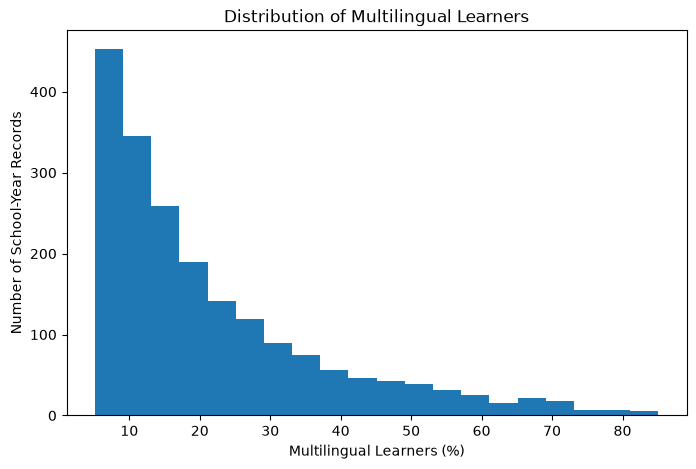

In [45]:
plt.figure(figsize=(8, 5))

plt.hist(
    school_year_context["multilingual_learner_pct"].dropna(),
    bins=20
)

plt.xlabel("Multilingual Learners (%)")
plt.ylabel("Number of School-Year Records")
plt.title("Distribution of Multilingual Learners")

plt.show()

Multilingual learner percentages are right-skewed, with most reported school-year records having lower ML percentages and fewer records having substantially higher percentages. The median ML percentage is 15.9%, compared with a mean of 21.5%. ML percentage also has substantial missing data, so relationships involving this variable are based on a smaller subset of school-year records.

In [46]:
# calculate grade-specific correlations between ML percentage and proficiency
ml_corr_by_grade = pd.DataFrame({
    "Math": math_df.groupby("grade").apply(
        lambda x: x["multilingual_learner_pct"].corr(
            x["proficient_pct_numeric"]
        ),
        include_groups=False
    ),
    "ELA": ela_df.groupby("grade").apply(
        lambda x: x["multilingual_learner_pct"].corr(
            x["proficient_pct_numeric"]
        ),
        include_groups=False
    )
})

ml_corr_by_grade

,Math,ELA
grade,,
3,-0.416850,-0.465145
4,-0.404965,-0.438628
5,-0.388006,-0.409061
6,-0.357688,-0.337846
7,-0.329498,-0.391462
8,-0.146366,-0.367674


Multilingual learner percentage is negatively associated with proficiency within each grade for both Math and ELA. The relationship is relatively consistent across grades for ELA and across grades 3–7 for Math, while the Math relationship is weaker in Grade 8. These results are descriptive and should be interpreted with consideration of the substantial missing data for multilingual learner percentage.

### Relationships Among School Characteristics

Correlations among school-level characteristics are examined to identify potentially overlapping predictors before regression modeling.

In [47]:
# examine correlations among candidate predictors to identify variables
# that may contain substantial overlapping information
predictor_corr = school_year_context[context_cols].corr()

predictor_corr.round(2)

,attendance_pct,chronic_absentee_pct,more_20_pct,farms_pct,multilingual_learner_pct,students_with_disabilities_pct,economically_disadvantaged_pct,gifted_talented_pct
attendance_pct,1.00,-0.92,-0.94,-0.52,-0.07,-0.20,-0.60,0.12
chronic_absentee_pct,-0.92,1.00,0.98,0.71,0.18,0.18,0.74,-0.20
more_20_pct,-0.94,0.98,1.00,0.63,0.09,0.16,0.69,-0.14
farms_pct,-0.52,0.71,0.63,1.00,0.42,0.14,0.93,-0.23
multilingual_learner_pct,-0.07,0.18,0.09,0.42,1.00,-0.19,0.32,-0.16
students_with_disabilities_pct,-0.20,0.18,0.16,0.14,-0.19,1.00,0.16,-0.20
economically_disadvantaged_pct,-0.60,0.74,0.69,0.93,0.32,0.16,1.00,-0.26
gifted_talented_pct,0.12,-0.20,-0.14,-0.23,-0.16,-0.20,-0.26,1.00


Several school-level characteristics are strongly correlated. The three attendance-related measures contain substantial overlapping information, with absolute correlations ranging from 0.92 to 0.98. FARMS and economically disadvantaged percentages are also highly correlated (r = 0.93). In addition, chronic absenteeism is positively correlated with both FARMS (r = 0.71) and economically disadvantaged percentage (r = 0.74).


### School Size

In [48]:
# summarize school enrollment size before examining
# its relationship with proficiency
school_year_context["total_student_count"].describe()

count    3349.000000
mean      523.716930
std       240.344583
min        12.000000
25%       357.000000
50%       497.000000
75%       659.000000
max      2251.000000
Name: total_student_count, dtype: float64

In [49]:
# calculate the correlation between school size and proficiency
# separately for Math and ELA
df.groupby("subject").apply(
    lambda x: x["total_student_count"].corr(
        x["proficient_pct_numeric"]
    ),
    include_groups=False
)

subject
ELA     0.176785
Math    0.048435
dtype: float64

School size has only a weak positive correlation with proficiency, with correlations of approximately 0.05 for Math and 0.18 for ELA. Compared with several of the other school characteristics examined, total student count does not show a strong linear relationship with proficiency.

### Candidate Predictors and Complete-Case Sample Size
Before regression modeling, data availability is examined for candidate predictors to determine how different model specifications would affect the analytical sample.

In [50]:
# check data availability for variables being considered for regression
model_cols = [
    "proficient_pct_numeric",
    "attendance_pct",
    "chronic_absentee_pct",
    "farms_pct",
    "multilingual_learner_pct",
    "students_with_disabilities_pct",
    "gifted_talented_pct"
]

df[model_cols].notna().sum().to_frame("non_missing").assign(
    pct_available=lambda x: (x["non_missing"] / len(df) * 100).round(1)
)

,non_missing,pct_available
proficient_pct_numeric,21707,98.2
attendance_pct,19618,88.8
chronic_absentee_pct,21753,98.4
farms_pct,20429,92.4
multilingual_learner_pct,12637,57.2
students_with_disabilities_pct,21175,95.8
gifted_talented_pct,14664,66.3


Most candidate predictors have relatively high data availability, but multilingual learner and gifted/talented percentages have substantially more missing data. Only 57.2% of observations have reported multilingual learner percentages and 66.3% have reported gifted/talented percentages.

Including variables with substantial missingness in a regression model may considerably reduce the number of observations available for analysis. The tradeoff between including these characteristics and retaining a larger analytical sample will therefore be considered during model development.

In [51]:
# define a core model using predictors with relatively high data availability
core_model_cols = [
    "proficient_pct_numeric",
    "grade",
    "subject",
    "year",
    "chronic_absentee_pct",
    "farms_pct",
    "students_with_disabilities_pct"
]

# add ML and GT to evaluate how much the complete-case sample 
# would decrease if these variables were required
full_model_cols = core_model_cols + [
    "multilingual_learner_pct",
    "gifted_talented_pct"
]

print(
    "Core model complete observations:",
    df[core_model_cols].dropna().shape[0]
)

print(
    "Full model complete observations:",
    df[full_model_cols].dropna().shape[0]
)

Core model complete observations: 19530
Full model complete observations: 7509


Using a core set of predictors consisting of grade, subject, year, chronic absenteeism, FARMS, and students with disabilities retains 19,530 complete observations. Adding multilingual learner and gifted/talented percentages reduces the complete-case sample to 7,509 observations.

Because including ML and GT would substantially reduce the analytical sample, these variables may be better evaluated in additional models rather than requiring them in the primary model.

In [52]:
# check whether smaller complete-case sample remains 
# reasonably distributed across subjects and grades
full_model_complete = df.dropna(subset=full_model_cols)

pd.crosstab(
    full_model_complete["grade"],
    full_model_complete["subject"]
)

subject,ELA,Math
grade,,
3,926,926
4,929,929
5,930,930
6,334,334
7,319,319
8,320,313


The complete-case sample that includes ML and GT remains similarly distributed between Math and ELA within each grade. However, as in the full analysis dataset, grades 6–8 contain fewer observations than grades 3–5. This difference should be considered when comparing results across grade levels.

### Proficiency Distribution and Low-Bounded Math Values

The distribution of the outcome variable is examined before regression modeling, with particular attention to low-bounded Math proficiency values.

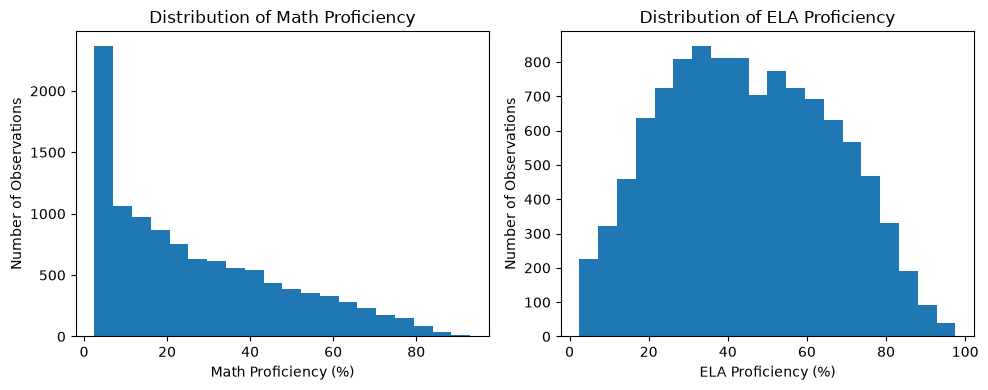

In [53]:
fig, axarr = plt.subplots(1, 2, figsize=(10, 4))

axarr[0].hist(
    math_df["proficient_pct_numeric"].dropna(),
    bins=20
)
axarr[0].set_xlabel("Math Proficiency (%)")
axarr[0].set_ylabel("Number of Observations")
axarr[0].set_title("Distribution of Math Proficiency")

axarr[1].hist(
    ela_df["proficient_pct_numeric"].dropna(),
    bins=20
)
axarr[1].set_xlabel("ELA Proficiency (%)")
axarr[1].set_ylabel("Number of Observations")
axarr[1].set_title("Distribution of ELA Proficiency")

plt.tight_layout()
plt.show()

Math and ELA proficiency have substantially different distributions. Math proficiency is strongly right-skewed, with a large concentration of observations at the lower end of the distribution. This concentration is influenced in part by low-bounded MCAP values (`<= 5%`), which are represented as 2.5% in the analysis data.

ELA proficiency is more broadly distributed and substantially less skewed than Math proficiency. These differences in outcome distributions, along with the grade-level patterns identified earlier, will be considered when developing and evaluating regression models.

In [54]:
# count math observations represented by the 2.5% replacement value
# for low-bounded proficiency (reported as <= 5%)
math_low_bounded_by_grade = (
    math_df.groupby("grade")["proficient_pct_numeric"]
    .apply(lambda x: (x == 2.5).sum())
)

math_low_bounded_by_grade

grade
3     78
4    225
5    311
6    306
7    311
8    552
Name: proficient_pct_numeric, dtype: int64

In [55]:
# calculate the percentage of Math observations in each grade
# represented by the low-bounded 2.5% value
math_low_bounded_pct_by_grade = (
    math_df.groupby("grade")["proficient_pct_numeric"]
    .apply(lambda x: (x == 2.5).mean() * 100)
)

math_low_bounded_pct_by_grade.round(1)

grade
3     3.0
4     8.6
5    11.9
6    27.9
7    29.6
8    52.9
Name: proficient_pct_numeric, dtype: float64

Low-bounded Math proficiency values become increasingly common in the later grades. The percentage of Math observations represented as 2.5% increases from 3.0% in Grade 3 to 27.9% in Grade 6, 29.6% in Grade 7, and 52.9% in Grade 8.

Therefore, the large concentration of low Math proficiency values in the later grades, particularly Grade 8, should not be interpreted as observations with exact proficiency rates of 2.5%. These values represent reported proficiency rates of 5% or less.

### Stability of Relationships Across Years

The relationships between proficiency and selected school characteristics are compared across 2023–2025 to determine whether the overall associations observed earlier are relatively consistent over time. This provides a compact check for year-to-year differences without separately analyzing every grade-year combination.

In [56]:
# focus on three major school characteristics that showed
# relatively strong relationships with proficiency
year_relationship_cols = [
    "attendance_pct",
    "chronic_absentee_pct",
    "farms_pct"
]

# calculate correlations with proficiency separately for each year and 
# subject to check whether the relationships are stable over time
year_corr = (
    df.groupby(["year", "subject"])[
        year_relationship_cols + ["proficient_pct_numeric"]
    ]
    .corr()["proficient_pct_numeric"]
    .drop("proficient_pct_numeric", level=2)
    .unstack("subject")
)

year_corr.round(3)

subject                      ELA   Math
year                                   
2023 attendance_pct        0.630  0.497
     chronic_absentee_pct -0.733 -0.585
     farms_pct            -0.814 -0.704
2024 attendance_pct        0.585  0.488
     chronic_absentee_pct -0.718 -0.601
     farms_pct            -0.829 -0.708
2025 attendance_pct        0.580  0.478
     chronic_absentee_pct -0.695 -0.568
     farms_pct            -0.816 -0.669

The relationships between proficiency and the selected school characteristics are relatively consistent across 2023–2025. Attendance is positively associated with proficiency in both subjects in each year, while chronic absenteeism and FARMS percentage are negatively associated with proficiency.

The direction and general magnitude of these correlations remain fairly stable across the three years, suggesting that the overall relationships observed earlier are not driven by a single year. Year will still be accounted for in later statistical models.